In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 200)
pd.set_option("display.max_rows", 200)

os.makedirs("reports/figures", exist_ok=True)
os.makedirs("models", exist_ok=True)

In [2]:
# load the data
test = pd.read_csv("/Users/EXOTISCH TECH/Desktop/sms-spam-detector/data/processed/test.csv")
X_test = test["clean_message"]
y_test = test["label_num"]

print("Test set:", test.shape)
print("Spam % in test:", round(y_test.mean() * 100, 2))

tuned = {
    "Naive Bayes (tuned)":         joblib.load("/Users/EXOTISCH TECH/Desktop/sms-spam-detector/models/nb_tuned.pkl"),
    "Logistic Regression (tuned)": joblib.load("/Users/EXOTISCH TECH/Desktop/sms-spam-detector/models/lr_tuned.pkl"),
    "Linear SVM (tuned)":          joblib.load("/Users/EXOTISCH TECH/Desktop/sms-spam-detector/models/svm_tuned.pkl"),
}

# Show the tuned settings so you can quote them in your report
for name, est in tuned.items():
    print(f"\n{name}")
    print("  TF-IDF:", {k: v for k, v in est.named_steps["tfidf"].get_params().items()
                        if k in ["ngram_range", "min_df", "max_df", "sublinear_tf"]})
    print("  Classifier:", est.named_steps["clf"])

Test set: (1031, 3)
Spam % in test: 12.42

Naive Bayes (tuned)
  TF-IDF: {'max_df': 1.0, 'min_df': 1, 'ngram_range': (1, 2), 'sublinear_tf': True}
  Classifier: MultinomialNB(alpha=0.1)

Logistic Regression (tuned)
  TF-IDF: {'max_df': 1.0, 'min_df': 3, 'ngram_range': (1, 1), 'sublinear_tf': True}
  Classifier: LogisticRegression(C=50, class_weight='balanced', max_iter=2000,
                   random_state=42)

Linear SVM (tuned)
  TF-IDF: {'max_df': 1.0, 'min_df': 1, 'ngram_range': (1, 2), 'sublinear_tf': True}
  Classifier: LinearSVC(C=5, class_weight='balanced', random_state=42)


## choosing the best model

In [3]:
cv_scores = pd.read_csv("/Users/EXOTISCH TECH/Desktop/sms-spam-detector/models/cv_scores.csv")
name_map = {"nb": "Naive Bayes (tuned)",
            "lr": "Logistic Regression (tuned)",
            "svm": "Linear SVM (tuned)"}
cv_scores["model"] = cv_scores["model"].map(name_map)
cv_scores = cv_scores.set_index("model").round(4)
display(cv_scores.sort_values("cv_f1", ascending=False))

best_name = cv_scores["cv_f1"].idxmax()
best_model = tuned[best_name]
print("Best model by CV F1:", best_name)

,cv_f1
model,
Logistic Regression (tuned),0.9470
Linear SVM (tuned),0.9458
Naive Bayes (tuned),0.9425


Best model by CV F1: Logistic Regression (tuned)


## Evaluate all tuned models on the test se

In [ ]:
final_rows, final_preds = [], {}
for name, est in tuned.items():
    y_pred = est.predict(X_test)
    final_preds[name] = y_pred
    final_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (spam)": precision_score(y_test, y_pred),
        "Recall (spam)": recall_score(y_test, y_pred),
        "F1 (spam)": f1_score(y_test, y_pred),
    })

final_df = pd.DataFrame(final_rows).set_index("Model").round(4)
final_df.to_csv("/Users/EXOTISCH TECH/Desktop/sms-spam-detector/reports/final_test_results.csv")
final_df.sort_values("F1 (spam)", ascending=False)

,Accuracy,Precision (spam),Recall (spam),F1 (spam)
Model,,,,
Logistic Regression (tuned),0.9903,0.9758,0.9453,0.9603
Linear SVM (tuned),0.9874,0.9752,0.9219,0.9478
Naive Bayes (tuned),0.9874,0.9832,0.9141,0.9474


## detailed classification report

In [7]:
for name, y_pred in final_preds.items():
    print(f"===== {name} =====")
    print(classification_report(y_test, y_pred, target_names=["ham", "spam"]))

===== Naive Bayes (tuned) =====
              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       903
        spam       0.98      0.91      0.95       128

    accuracy                           0.99      1031
   macro avg       0.99      0.96      0.97      1031
weighted avg       0.99      0.99      0.99      1031

===== Logistic Regression (tuned) =====
              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       903
        spam       0.98      0.95      0.96       128

    accuracy                           0.99      1031
   macro avg       0.98      0.97      0.98      1031
weighted avg       0.99      0.99      0.99      1031

===== Linear SVM (tuned) =====
              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       903
        spam       0.98      0.92      0.95       128

    accuracy                           0.99      1031
   macro avg       0.98  

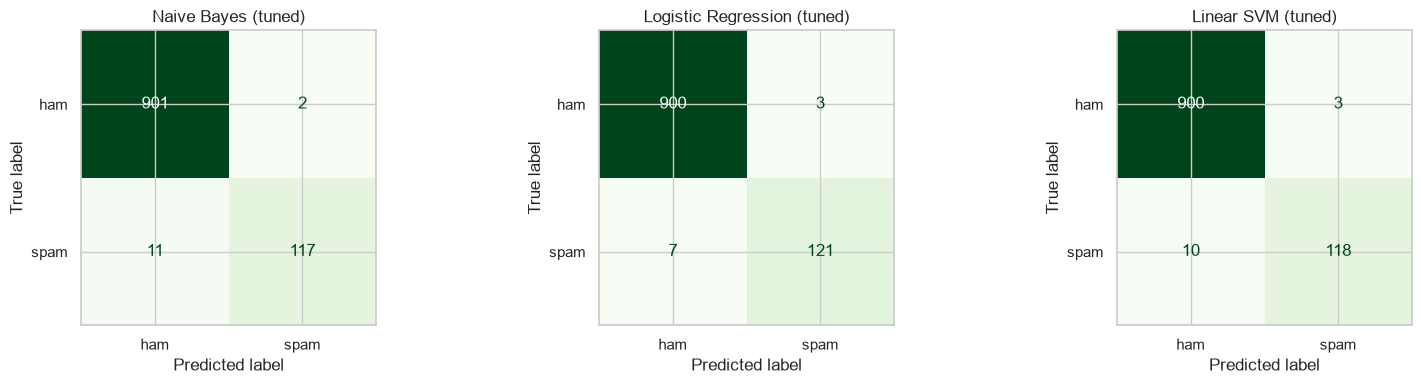

In [8]:
# confusion matrix
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, (name, y_pred) in zip(ax, final_preds.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=["ham", "spam"],
        cmap="Greens", ax=a, colorbar=False
    )
    a.set_title(name)
plt.tight_layout()
plt.savefig("/Users/EXOTISCH TECH/Desktop/sms-spam-detector/reports/figures/confusion_matrices_tuned.png", dpi=200, bbox_inches="tight")
plt.show()

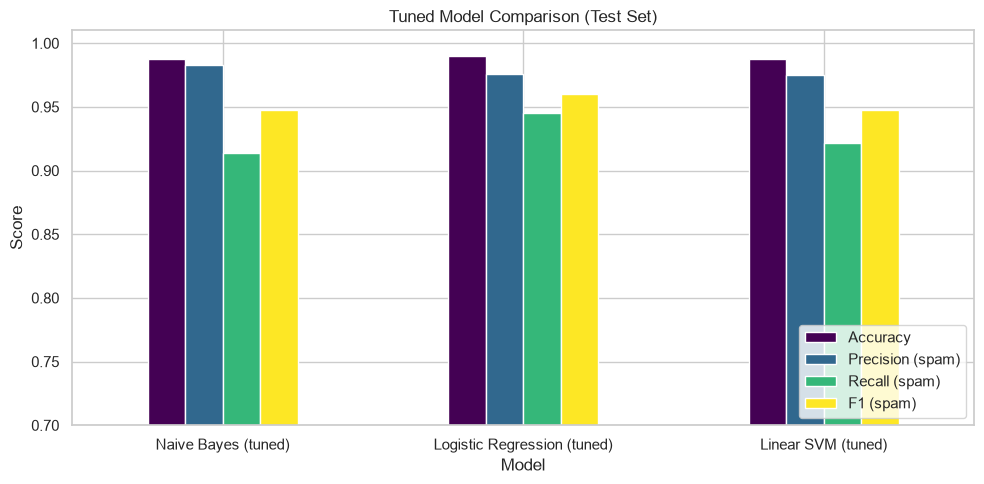

In [9]:
# metrics comparison
# /Users/EXOTISCH TECH/Desktop/sms-spam-detector/
final_df.plot(kind="bar", figsize=(10, 5), ylim=(0.7, 1.01), colormap="viridis")
plt.title("Tuned Model Comparison (Test Set)")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("/Users/EXOTISCH TECH/Desktop/sms-spam-detector/reports/figures/model_comparison_tuned.png", dpi=200, bbox_inches="tight")
plt.show()


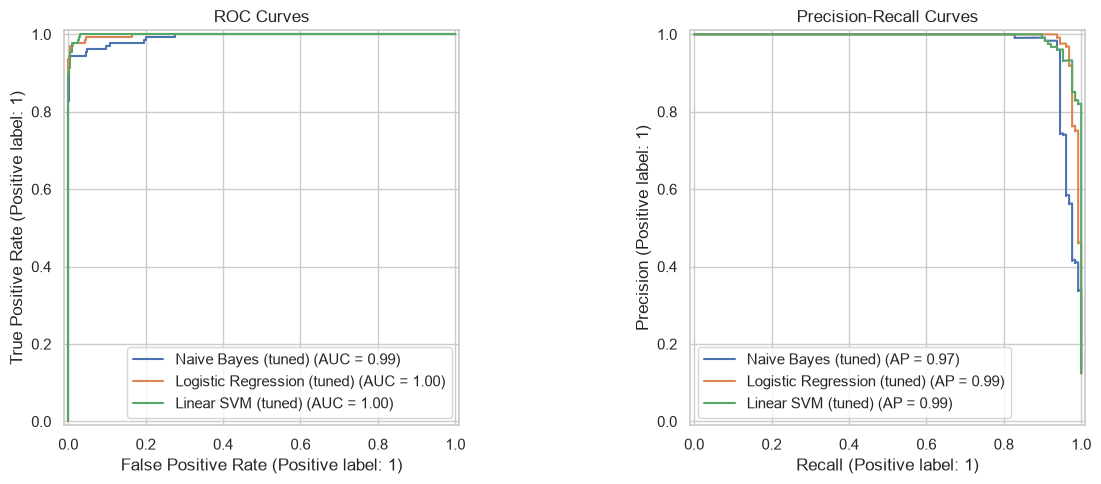

In [10]:
# ROC and precision-recall curve
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name, est in tuned.items():
    RocCurveDisplay.from_estimator(est, X_test, y_test, name=name, ax=ax[0])
    PrecisionRecallDisplay.from_estimator(est, X_test, y_test, name=name, ax=ax[1])
ax[0].set_title("ROC Curves")
ax[1].set_title("Precision-Recall Curves")
plt.tight_layout()
plt.savefig("/Users/EXOTISCH TECH/Desktop/sms-spam-detector/reports/figures/roc_pr_curves.png", dpi=200, bbox_inches="tight")
plt.show()


## : Error analysis: false positives and false negatives

In [11]:
err_df = test[["message", "clean_message", "label_num"]].copy()
err_df["predicted"] = best_model.predict(X_test)

false_pos = err_df[(err_df["label_num"] == 0) & (err_df["predicted"] == 1)]
false_neg = err_df[(err_df["label_num"] == 1) & (err_df["predicted"] == 0)]

print("Model analysed:", best_name)
print(f"False positives (ham flagged as spam): {len(false_pos)}")
print(f"False negatives (spam missed):         {len(false_neg)}")

Model analysed: Logistic Regression (tuned)
False positives (ham flagged as spam): 3
False negatives (spam missed):         7


In [12]:
print("FALSE POSITIVES: legitimate messages wrongly flagged as spam\n")
display(false_pos[["message"]])

FALSE POSITIVES: legitimate messages wrongly flagged as spam



,message
48,"Hey...Great deal...Farm tour 9am to 5pm $95/pax, $50 deposit by 16 May"
499,S.this will increase the chance of winning.
925,I love to wine and dine my lady!


In [13]:
print("FALSE NEGATIVES: spam messages the model missed\n")
display(false_neg[["message"]])

FALSE NEGATIVES: spam messages the model missed



,message
272,thesmszone.com lets you send free anonymous and masked messages..im sending this message from there..do you see the potential for abuse???
489,"LookAtMe!: Thanks for your purchase of a video clip from LookAtMe!, you've been charged 35p. Think you can do better? Why not send a video in a MMSto 32323."
526,Monthly password for wap. mobsi.com is 391784. Use your wap phone not PC.
833,Welcome! Please reply with your AGE and GENDER to begin. e.g 24M
851,dating:i have had two of these. Only started after i sent a text to talk sport radio last week. Any connection do you think or coincidence?
992,Guess who am I?This is the first time I created a web page WWW.ASJESUS.COM read all I wrote. I'm waiting for your opinions. I want to be your friend 1/1
1007,Sorry I missed your call let's talk when you have the time. I'm on 07090201529


In [14]:
# verify if the the missed spam messages look different? (length, digits, links)
def quick_stats(frame):
    return pd.Series({
        "avg_chars": frame["message"].str.len().mean(),
        "avg_digits": frame["message"].str.count(r"\d").mean(),
        "has_url_%": frame["message"].str.contains(r"http|www\.", case=False).mean() * 100,
    })

caught_spam = err_df[(err_df["label_num"] == 1) & (err_df["predicted"] == 1)]
pd.DataFrame({
    "Spam caught": quick_stats(caught_spam),
    "Spam missed": quick_stats(false_neg),
}).round(2)

,Spam caught,Spam missed
avg_chars,139.55,114.29
avg_digits,16.95,4.00
has_url_%,9.92,14.29


## Most influential words (Part 13)

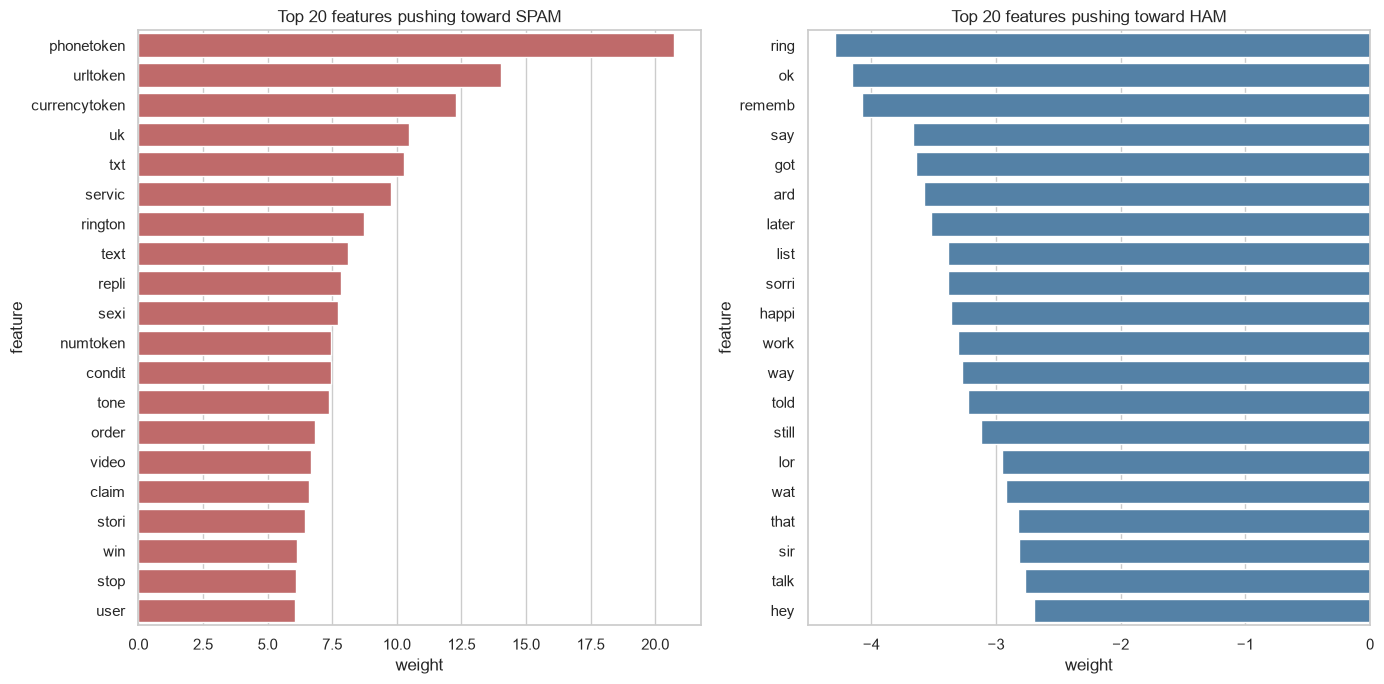

In [16]:
lr_pipe = tuned["Logistic Regression (tuned)"]
vec = lr_pipe.named_steps["tfidf"]
clf = lr_pipe.named_steps["clf"]

features = np.array(vec.get_feature_names_out())
coefs = clf.coef_.ravel()
order = coefs.argsort()

top_spam = pd.DataFrame({"feature": features[order[::-1][:20]],
                         "weight": coefs[order[::-1][:20]]})
top_ham = pd.DataFrame({"feature": features[order[:20]],
                        "weight": coefs[order[:20]]})

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
sns.barplot(data=top_spam, y="feature", x="weight", ax=ax[0], color="indianred")
ax[0].set_title("Top 20 features pushing toward SPAM")
sns.barplot(data=top_ham, y="feature", x="weight", ax=ax[1], color="steelblue")
ax[1].set_title("Top 20 features pushing toward HAM")
plt.tight_layout()
plt.savefig("/Users/EXOTISCH TECH/Desktop/sms-spam-detector/reports/figures/top_features_lr.png", dpi=200, bbox_inches="tight")
plt.show()

In [17]:
# save the final model
joblib.dump(best_model, "/Users/EXOTISCH TECH/Desktop/sms-spam-detector/models/spam_pipeline.pkl")

# Reload check
loaded = joblib.load("/Users/EXOTISCH TECH/Desktop/sms-spam-detector/models/spam_pipeline.pkl")
sample = X_test.iloc[:5]
print("Reloaded model reproduces predictions:",
      (loaded.predict(sample) == best_model.predict(sample)).all())
print("Saved final model:", best_name)

Reloaded model reproduces predictions: True
Saved final model: Logistic Regression (tuned)


In [18]:
def explain(idx, top=6):
    row = err_df.loc[idx]
    vec_row = vec.transform([row["clean_message"]])
    contrib = vec_row.multiply(coefs).toarray().ravel()
    top_idx = contrib.argsort()[::-1][:top]
    print(f"[{idx}] {row['message'][:80]}")
    print(pd.DataFrame({"feature": features[top_idx], "contribution": contrib[top_idx]}
                       ).query("contribution > 0").round(3).to_string(index=False), "\n")

for i in false_pos.index:
    explain(i)

[48] Hey...Great deal...Farm tour 9am to 5pm $95/pax, $50 deposit by 16 May
      feature  contribution
currencytoken         4.957
     numtoken         2.154
           pm         0.384
         tour         0.175 

[499] S.this will increase the chance of winning.
feature  contribution
    win         4.105
  chanc         2.108 

[925] I love to wine and dine my lady!
feature  contribution
   wine         3.302
   ladi         3.080 



### This shows which words pushed each false positive towards spam